# Skeleton extraction from video

**Goals of this notebook:**
1. Extract the patient's body joints from every video with a pose estimation model (YOLO11 pose)
2. Check the quality of the joints visually and with numbers
3. Save one skeleton file per video to Google Drive for the next steps

In [ ]:
# Connect Google Drive: the skeleton files are saved there permanently.

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Download the dataset

In [ ]:
# Ask the Figshare API for the list of files in the dataset.

import cv2
import numpy as np
import requests

article_id = 14984667
response = requests.get(f"https://api.figshare.com/v2/articles/{article_id}")
files = response.json()["files"]

In [ ]:
# Download every file of the dataset into /content/data.

!mkdir -p /content/data

for f in files:
    name = f["name"]
    url = f["download_url"]
    !wget -c -q --show-progress -O "/content/data/{name}" "{url}"

/content/data/Video 100%[===================>]   4.67G  19.4MB/s    in 4m 7s   
/content/data/PDFEi 100%[===================>]  12.01K  --.-KB/s    in 0s      
/content/data/IMU.z 100%[===================>] 152.50M  14.5MB/s    in 12s     


In [ ]:
# Unzip all downloaded zip files, then delete the zips to save disk space.
!cd /content/data && for z in *.zip; do unzip -q "$z" && rm "$z"; done
!ls -lh /content/data

total 32K
drwxr-xr-x 2 root root  12K Nov  5 09:18 IMU
-rw-r--r-- 1 root root  13K Nov 21  2021 PDFEinfo.csv
drwxr-xr-x 2 root root 4.0K Nov  5 09:19 Videos


In [ ]:
# Main data folder.
from pathlib import Path

DATA_DIR= Path('/content/data')

## 2. Pose estimation model: YOLO11 pose
MediaPipe Pose was tested first (separate notebook) but failed on these videos: the camera shows the patient only from the waist or the thighs down, and MediaPipe needs the face and upper body to find a person. YOLO11 pose detects people without the face and worked well.

YOLO gives **17 joints** (COCO format) for each person. Each joint has x, y (normalized: fraction of the image width and height, 0 to 1) and a confidence (0 to 1).
The leg joints checked in this notebook:

| Index | Joint |
|---|---|
| 11, 12 | left hip, right hip |
| 13, 14 | left knee, right knee |
| 15, 16 | left ankle, right ankle |

Model size: `m` (medium), a balance between accuracy and speed. Run this notebook on a GPU.

In [ ]:
# Install Ultralytics and load the YOLO11 pose model (medium size).

!pip install ultralytics
from ultralytics import YOLO

model = YOLO("yolo11m-pose.pt")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 57.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## 3. Skeleton extraction function
For every frame of a video, the function keeps the joints of **one person, the patient**. Other people (clinicians) are often visible, so a selection rule is needed. The function has two rules:
- `rule="center"` (default, used for all trials): the person whose box centre is **closest to the middle of the image**.
- `rule="lowest"`: the person **closest to the camera**, i.e. whose box reaches lowest in the image. It is used only for PDFE24_1 (see section 12).

If no person is found, the frame is filled with NaN. This keeps **one row per video frame**, so the skeleton stays aligned in time with the video.

Output shape: **(number of frames, 17 joints, 3 values: x, y, confidence)**.

In [ ]:
# Read a video frame by frame and return the patient's 17 joints for every frame.
# Returns an array of shape (n_frames, 17, 3): x, y (normalized 0-1) and confidence.

def extract_skeleton(video_path, rule="center"):
    cap = cv2.VideoCapture(str(video_path))
    frames = []

    while True:
        ok, frame = cap.read()
        if not ok:
            break

        result = model(frame, verbose=False)[0]

        # No person found in this frame: fill with NaN
        if result.keypoints is None or result.keypoints.conf is None or len(result.boxes) == 0:
           array=np.full((17, 3), np.nan)

        else:
            kp = result.keypoints.xyn.cpu().numpy()
            conf = result.keypoints.conf.cpu().numpy()
            if rule == "center":
              # Keep the person whose box centre is closest to the middle of the image
              box_x = result.boxes.xywhn[:, 0].cpu().numpy()    # x of the centre of each person's box
              patient = np.argmin(np.abs(box_x - 0.5))
            elif rule == "lowest":
                # Keep the person closest to the camera: box bottom edge lowest in the image
                box_bottom = result.boxes.xyxyn[:, 3].cpu().numpy()
                patient = np.argmax(box_bottom)

            array=np.column_stack([kp[patient], conf[patient]])

        frames.append(array)
    cap.release()
    return np.stack(frames)

## 4. Test on one video

In [ ]:
# Run the extraction on one video and check: shape, frames without a person,
# and the average confidence of the two ankles.
video_path = '/content/data/Videos/PDFE16_2.mp4'
skeleton_test = extract_skeleton(video_path)
print("Shape:", skeleton_test.shape)

no_person = np.isnan(skeleton_test[:, 0, 0]).sum()
print(f"Frames with no person detected: {no_person}")
print("Average confidence, left ankle (15):", np.nanmean(skeleton_test[:, 15, 2]))
print("Average confidence, right ankle (16):", np.nanmean(skeleton_test[:, 16, 2]))

Shape: (3606, 17, 3)
Frames with no person detected: 0
Average confidence, left ankle (15): 0.9858764
Average confidence, right ankle (16): 0.9857308


**Result:** 3,606 frames, a person found in every frame, average ankle confidence ≈ 0.99.

## 5. Visual quality check
Numbers alone can hide errors (for example, joints placed on the wrong person). The 6 leg joints are drawn on 3 frames (start, middle, end) to check by eye that they sit on the **patient's** legs. Only joints with confidence ≥ 0.5 are drawn.

In [ ]:
# Draw the 6 leg joints (11-16) on the first, middle, and last frame of a video.
import os
import matplotlib.pyplot as plt

def display_joint(video_path):

    video=cv2.VideoCapture(video_path)
    skeleton=extract_skeleton(video_path)
    n_frames = len(skeleton)

    for n in [0, n_frames // 2, n_frames - 1]:
        video.set(cv2.CAP_PROP_POS_FRAMES, n)   # jump directly to frame n
        ok, frame = video.read()
        if not ok:
            continue
        height, width = frame.shape[:2]

        for j in range (11,17):
              x=skeleton[n,j,0]
              y=skeleton[n,j,1]
              conf = skeleton[n,j,2]
              if np.isnan(x) or np.isnan(y) or conf <0.5:
                continue
              pixel_x = int(x * width)
              pixel_y = int(y * height)
              cv2.circle(frame, (pixel_x, pixel_y), 5, (0, 255, 0), -1)
        plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        plt.title(f"frame_number = {n}")
        plt.axis("off")
        plt.show()
    video.release()

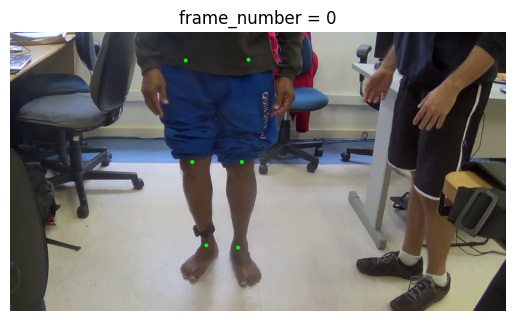

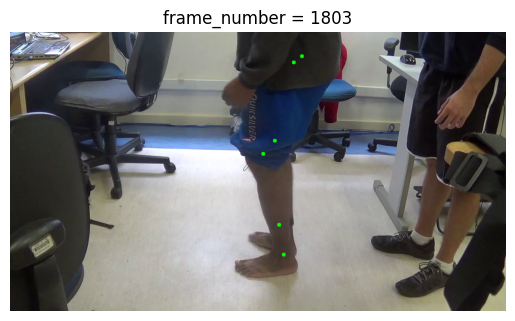

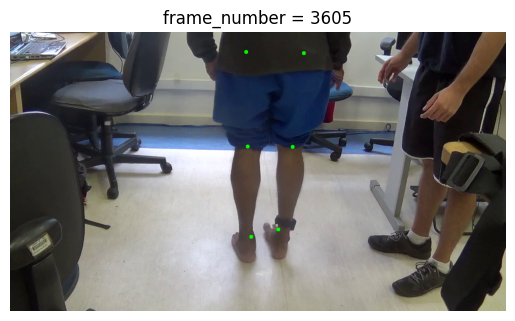

In [ ]:
# Visual check on PDFE16_2.
display_joint('/content/data/Videos/PDFE16_2.mp4')

**Result:** hips, knees, and ankles are placed on the patient's legs in all three views (front, side, back). The clinician on the right is not selected.

## 6. Extract and save the skeletons of all videos
The skeletons are saved to Google Drive (one `.npy` file per video). From now on, the heavy videos are no longer needed: the next steps use only these small files.

In [ ]:
# Folder on Google Drive where one skeleton file (.npy) per video is saved.
import os
skeleton_yolo = '/content/drive/MyDrive/skeleton_yolo'
os.makedirs(skeleton_yolo, exist_ok=True)

In [ ]:
# Delete PDFE24_1.npy so the save loop recreates it with the default rule ("center").
# Sections 7-11 then show the problem with this trial, and section 12 later
# replaces the file with the "lowest" rule. The notebook must run to the end,
# otherwise the 'center' version stays on Drive.
pdfe24_file = os.path.join(skeleton_yolo, "PDFE24_1.npy")
if os.path.exists(pdfe24_file):
    os.remove(pdfe24_file)
    print("Deleted PDFE24_1.npy: it will be recreated with the 'center' rule")

In [ ]:
# Extract the skeleton of every video and save it as <video name>.npy on Drive.
# Videos that already have a saved file are skipped, so the loop can continue
# where it stopped if Colab disconnects.

for file in sorted(os.listdir('/content/data/Videos')):
    if not file.lower().endswith('.mp4'):
       continue

    video_name = os.path.splitext(file)[0]
    video_skeleton_file = os.path.join(skeleton_yolo, f"{video_name}.npy")

    # Skip videos that were already processed
    if os.path.exists(video_skeleton_file):
        print(f"Skipping {file} (already saved)")
        continue
    video_path= os.path.join('/content/data/Videos', file)
    skeleton=extract_skeleton(video_path)

    # Save to a temp file first, then rename (safe against disconnects)
    tmp_file = video_skeleton_file + ".tmp.npy"
    np.save(tmp_file, skeleton)
    os.replace(tmp_file, video_skeleton_file)

Skipping PDFE01_1.mp4 (already saved)
Skipping PDFE01_2.mp4 (already saved)
Skipping PDFE02_1.mp4 (already saved)
Skipping PDFE03_1.mp4 (already saved)
Skipping PDFE03_2.mp4 (already saved)
Skipping PDFE03_3.mp4 (already saved)
Skipping PDFE04_1.mp4 (already saved)
Skipping PDFE05_1.mp4 (already saved)
Skipping PDFE06_1.mp4 (already saved)
Skipping PDFE06_2.mp4 (already saved)
Skipping PDFE07_1.mp4 (already saved)
Skipping PDFE07_3.mp4 (already saved)
Skipping PDFE08_1.mp4 (already saved)
Skipping PDFE09_1.mp4 (already saved)
Skipping PDFE09_2.mp4 (already saved)
Skipping PDFE10_1.mp4 (already saved)
Skipping PDFE10_2.mp4 (already saved)
Skipping PDFE10_3.mp4 (already saved)
Skipping PDFE11_1.mp4 (already saved)
Skipping PDFE11_2.mp4 (already saved)
Skipping PDFE12_1.mp4 (already saved)
Skipping PDFE13_1.mp4 (already saved)
Skipping PDFE14_1.mp4 (already saved)
Skipping PDFE14_2.mp4 (already saved)
Skipping PDFE14_3.mp4 (already saved)
Skipping PDFE15_1.mp4 (already saved)
Skipping PDF

## 7. Quality table of the saved skeletons
The **saved files** are checked (not recomputed), for the 71 trials with both video and IMU:
- `video_frames` – number of frames in the video
- `skeleton_frames` – number of frames in the saved skeleton; must equal `video_frames` (a difference of 1–2 frames can come from the video metadata)
- `%_no_person` – % of frames where no person was detected
- `%_legs_ok` – % of frames where **all 6 leg joints** have confidence > 0.5

In [ ]:
# Build a quality table from the saved skeleton files (71 trials).
# frame_difference = video_frames - skeleton_frames (should be about 0).
import pandas as pd
results=[]

for file in os.listdir('/content/data/Videos'):
    if not file.lower().endswith('.mp4'):
       continue
    trial=os.path.splitext(file)[0]
    if trial in ["PDFE10_3", "PDFE30_3"]:       # no IMU, not used
       continue

    # Number of frames in the video
    cap = cv2.VideoCapture(os.path.join('/content/data/Videos', file))
    video_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()

    # Load the saved skeleton
    skeleton = np.load(os.path.join(skeleton_yolo, f"{trial}.npy"))
    skeleton_frames=len(skeleton)
    no_person = np.isnan(skeleton[:, 0, 0]).sum()
    percent_no_person=(no_person/len(skeleton))*100
    percent_legs_ok=(skeleton[:, 11:17, 2] > 0.5).all(axis=1).mean() * 100
    results.append({"trial": trial,"video_frames": video_frames,"skeleton_frames":skeleton_frames,"%_no_person":percent_no_person,"%_legs_ok":percent_legs_ok})

results_df=pd.DataFrame(results)
results_df["frame_difference"] = results_df["video_frames"] - results_df["skeleton_frames"]

print(results_df.describe())
print(results_df.sort_values("%_legs_ok").head(5))    # the 5 worst trials


       video_frames  skeleton_frames  %_no_person   %_legs_ok  \
count     71.000000        71.000000         71.0   71.000000   
mean    3604.084507      3604.014085          0.0   80.825154   
std       51.678331        51.674944          0.0   33.556265   
min     3360.000000      3360.000000          0.0    0.000000   
25%     3605.500000      3605.500000          0.0   77.160114   
50%     3610.000000      3610.000000          0.0   99.972573   
75%     3619.000000      3619.000000          0.0  100.000000   
max     3688.000000      3688.000000          0.0  100.000000   

       frame_difference  
count         71.000000  
mean           0.070423  
std            0.257679  
min            0.000000  
25%            0.000000  
50%            0.000000  
75%            0.000000  
max            1.000000  
       trial  video_frames  skeleton_frames  %_no_person  %_legs_ok  \
34  PDFE19_2          3610             3610          0.0   0.000000   
17  PDFE19_1          3601            

**Result:** all 71 trials were checked.
- `frame_difference` is 0 or 1 for all trials, so the saved skeletons have one row per video frame.
- A person was detected in every frame of every video (`%_no_person` = 0).
- All 6 leg joints were detected with confidence > 0.5 in **80.8% of frames on average** (median 99.97%). Most trials are close to 100%, but a few are close to 0%: PDFE19_2 (0%), PDFE19_1 (0.2%), PDFE35_1 (0.9%), PDFE26_3 (2.9%), PDFE11_2 (3.9%). These trials are investigated below.

## 8. Investigation of the trials with low leg detection
The quality table shows a large spread in `%_legs_ok`: most trials are close to 100%, but some are close to 0%. These trials are listed and checked visually to find the cause.

In [ ]:
# List the trials where fewer than 50% of frames have all 6 leg joints detected.
bad = results_df[results_df["%_legs_ok"] < 50].sort_values("%_legs_ok")
print(len(bad), "trials below 50%")
print(bad[["trial", "%_legs_ok"]])

14 trials below 50%
       trial  %_legs_ok
34  PDFE19_2   0.000000
17  PDFE19_1   0.222222
39  PDFE35_1   0.916667
64  PDFE26_3   2.936288
63  PDFE11_2   3.884573
4   PDFE03_3   4.653084
5   PDFE30_1  13.465784
49  PDFE24_1  14.444444
50  PDFE27_1  19.578480
59  PDFE26_2  29.884106
37  PDFE21_3  31.277778
55  PDFE29_1  39.348079
43  PDFE34_1  40.608575
6   PDFE27_3  42.382271


**Result:** **14 of 71 trials** have fewer than 50% of frames with all 6 leg joints detected. The 5 worst are PDFE19_2, PDFE19_1, PDFE35_1, PDFE26_3, and PDFE11_2 (all below 4%).

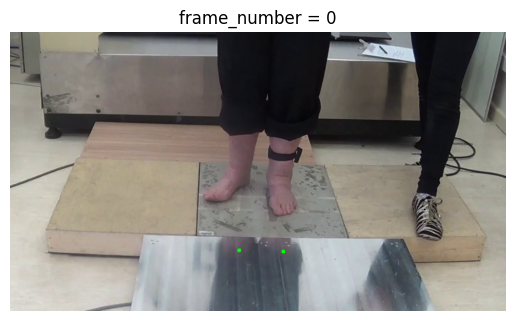

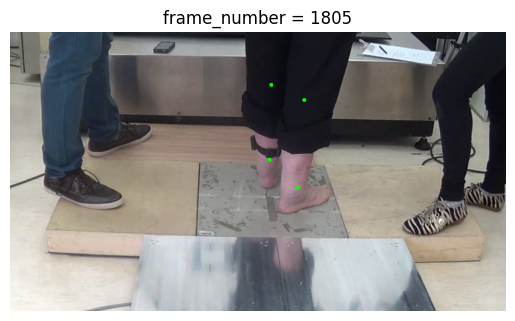

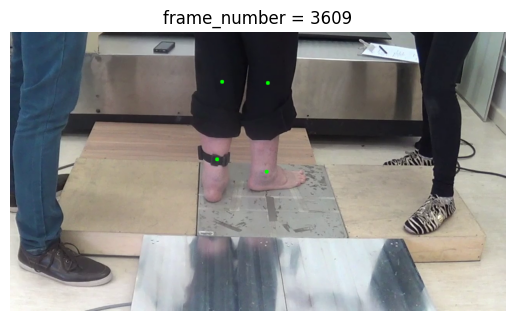

In [ ]:
# Visual check of the worst trial (PDFE19_2, 0% of frames with all 6 leg joints).
display_joint('/content/data/Videos/PDFE19_2.mp4')

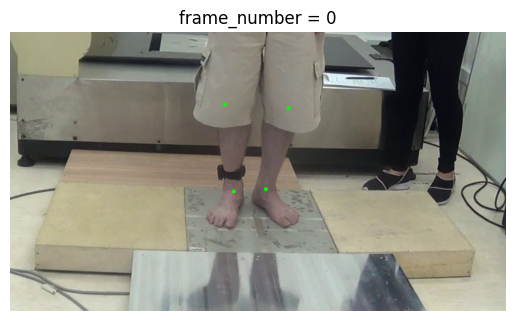

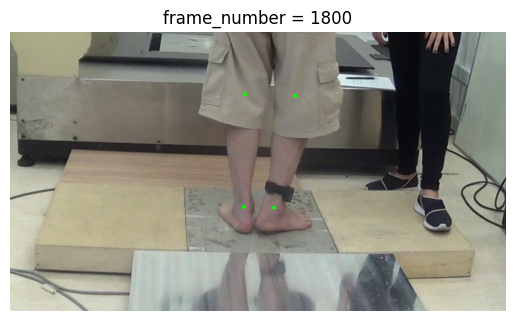

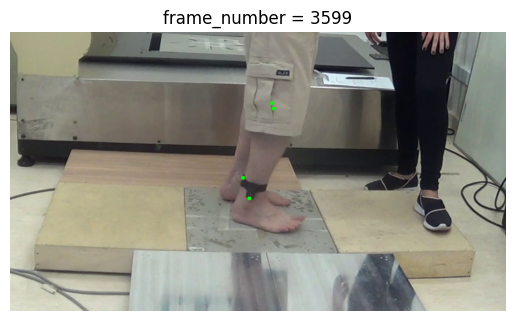

In [ ]:
# Visual check of PDFE35_1 (0.9% of frames with all 6 leg joints).
display_joint('/content/data/Videos/PDFE35_1.mp4')

**Findings from the images:**
1. **Two camera setups.** In most trials (e.g. PDFE16_2), the camera shows the patient from the waist down, so hips, knees, and ankles are visible. In some trials (e.g. PDFE19_2, PDFE35_1), the camera is lower and closer and shows the legs only from about mid-thigh down: **the hips are outside the image**. Because `%_legs_ok` requires all 6 joints, including the hips, these trials score close to 0% **even when the knees and ankles are detected correctly** (for example, PDFE35_1 in all 3 frames).
2. **Mirror reflection.** In these trials, a metal plate in front of the patient reflects the legs. In frame 0 of PDFE19_2, the joints are placed on the **reflection** instead of the real legs: the reflection is detected as a second person and selected.

## 9. Quality with knees and ankles only
**Decision:** only **4 joints are used for all trials: left and right knee, left and right ankle (13–16)**. The hips are dropped.
- Knees and ankles are visible in **both** camera setups, so all trials get the same input.
- The knee → ankle segment is the **shank**, where the IMU is attached. This is needed for aligning video and IMU (next step).
- Freezing of gait shows mainly in the lower legs (trembling, shuffling), so little information is lost.

The quality table is computed again with the new measure `%_knees_ankles_ok`.

In [ ]:
# Same quality table as in section 7, but the leg measure uses only knees and ankles:
# %_knees_ankles_ok = % of frames where joints 13-16 all have confidence > 0.5.
import pandas as pd
results=[]

for file in os.listdir('/content/data/Videos'):
    if not file.lower().endswith('.mp4'):
       continue
    trial=os.path.splitext(file)[0]
    if trial in ["PDFE10_3", "PDFE30_3"]:       # no IMU, not used
       continue

    # Number of frames in the video
    cap = cv2.VideoCapture(os.path.join('/content/data/Videos', file))
    video_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()

    # Load the saved skeleton
    skeleton = np.load(os.path.join(skeleton_yolo, f"{trial}.npy"))
    skeleton_frames=len(skeleton)
    no_person = np.isnan(skeleton[:, 0, 0]).sum()
    percent_no_person=(no_person/len(skeleton))*100
    percent_knees_ankles_ok = (skeleton[:, 13:17, 2] > 0.5).all(axis=1).mean() * 100
    results.append({"trial": trial,"video_frames": video_frames,"skeleton_frames":skeleton_frames,"%_no_person":percent_no_person,"%_knees_ankles_ok":percent_knees_ankles_ok})

results_df=pd.DataFrame(results)
results_df["frame_difference"] = results_df["video_frames"] - results_df["skeleton_frames"]

print(results_df.describe())
print(results_df.sort_values("%_knees_ankles_ok").head(5))    # the 5 worst trials


       video_frames  skeleton_frames  %_no_person  %_knees_ankles_ok  \
count     71.000000        71.000000         71.0          71.000000   
mean    3604.084507      3604.014085          0.0          99.304316   
std       51.678331        51.674944          0.0           3.885990   
min     3360.000000      3360.000000          0.0          68.277778   
25%     3605.500000      3605.500000          0.0          99.944491   
50%     3610.000000      3610.000000          0.0         100.000000   
75%     3619.000000      3619.000000          0.0         100.000000   
max     3688.000000      3688.000000          0.0         100.000000   

       frame_difference  
count         71.000000  
mean           0.070423  
std            0.257679  
min            0.000000  
25%            0.000000  
50%            0.000000  
75%            0.000000  
max            1.000000  
       trial  video_frames  skeleton_frames  %_no_person  %_knees_ankles_ok  \
49  PDFE24_1          3600            

**Result:** with knees and ankles only, the joints are detected with confidence > 0.5 in **99.3% of frames on average** (median 100%). The 5 worst trials are PDFE24_1 (68.3%), PDFE07_2 (91.4%), PDFE35_2 (97.8%), PDFE25_2 (98.2%), and PDFE19_2 (98.8%). Trials that scored close to 0% with 6 joints (e.g. PDFE19_2) are now close to 100%, which confirms that their low score was caused by the hips being outside the image.

In [ ]:
# List the trials where fewer than 50% of frames have all 4 knee and ankle joints detected.
bad = results_df[results_df["%_knees_ankles_ok"] < 50].sort_values("%_knees_ankles_ok")
print(len(bad), "trials below 50%")
print(bad[["trial", "%_knees_ankles_ok"]])

0 trials below 50%
Empty DataFrame
Columns: [trial, %_knees_ankles_ok]
Index: []


**Result:** **0 of 71 trials** are below 50%. Only PDFE24_1 (68.3%) and PDFE07_2 (91.4%) are below 97%.

A high confidence does not prove that the joints are on the **patient's** legs: another person, or the reflection in the metal plate, can also be detected with high confidence. Two more checks are therefore made:
- section 10: how often the **reflection** is selected
- section 11: how often **another person** is selected (person switches)

In the next steps, joints with confidence < 0.5 are treated as missing values.

## 10. Mirror reflection
In the trials with a metal plate, the plate reflects the legs, and the reflection can be detected as a person. The reflection is **upside down**: for a real standing person the knees are above the ankles (smaller y, because y grows downward), for the reflection the knees are below the ankles. The % of frames where the selected person is upside down is counted for every trial.

In [ ]:
# A real standing person has the knees ABOVE the ankles (smaller y; y grows downward).
# The reflection in the metal plate is upside down: knees BELOW ankles.
reflection_results = []
reflection_frames = {}

for trial in results_df["trial"]:
    sk = np.load(os.path.join(skeleton_yolo, f"{trial}.npy"))
    knee_y = sk[:, 13:15, 1].mean(axis=1)     # average y of both knees, per frame
    ankle_y = sk[:, 15:17, 1].mean(axis=1)    # average y of both ankles, per frame
    upside_down = knee_y > ankle_y            # True = probably the reflection
    reflection_frames[trial] = np.where(upside_down)[0]
    percent_reflection= upside_down.mean() * 100
    reflection_results.append({"trial": trial, "%_reflection":percent_reflection })

reflection_df = pd.DataFrame(reflection_results).sort_values("%_reflection", ascending=False)
print(reflection_df.head(10))
print((reflection_df["%_reflection"] > 1).sum(), "trials with more than 1% reflection frames")

       trial  %_reflection
65  PDFE07_2      1.205479
2   PDFE25_2      1.024931
58  PDFE35_2      0.221852
39  PDFE35_1      0.027778
34  PDFE19_2      0.027701
64  PDFE26_3      0.027701
7   PDFE32_1      0.027663
6   PDFE27_3      0.000000
5   PDFE30_1      0.000000
4   PDFE03_3      0.000000
2 trials with more than 1% reflection frames


**Result**: the selected person is upside down (knees below ankles, i.e. the reflection in the metal plate) in only a few frames: PDFE07_2 (1.2%, about 44 frames), PDFE25_2 (1.0%, about 37 frames), and PDFE35_2 (0.2%, about 8 frames). In four trials (PDFE35_1, PDFE19_2, PDFE26_3, PDFE32_1), it happens in a single frame. In all other trials, it never happens.

**Decision**: the reflection is rare, so YOLO is not re-run. Frames where the knees are below the ankles are set to missing in section 13.

## 11. Wrong person selected (person switches)
PDFE24_1 has the lowest score with knees and ankles (68.3%), so it is first checked visually.

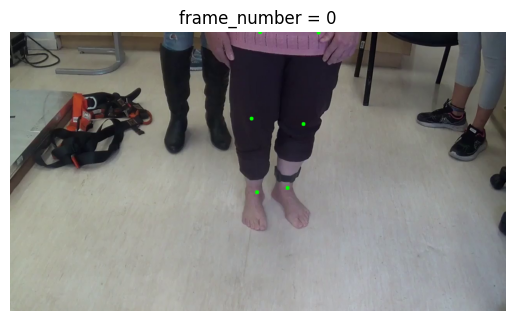

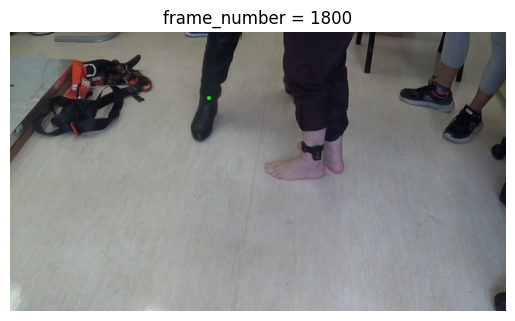

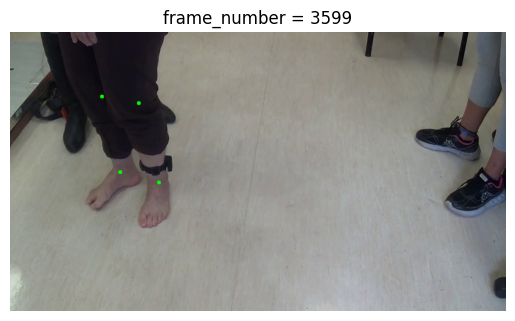

In [ ]:
# Visual check of PDFE24_1 (worst trial with knees and ankles), with the default rule ("center").
display_joint('/content/data/Videos/PDFE24_1.mp4')

In frame 1800, the joints are placed on the doctor’s boot instead of the patient. If the selected person changes between two frames, the ankles appear to ‘jump’ across the image, because a real ankle cannot move far in 1/30 s. Counting these jumps in all trials shows which trials have person switches.

In [ ]:
# A person switch shows up as a sudden jump of the ankles between two frames.
# In 1/30 s a real ankle cannot move more than a small part of the image width.
jump_results = []
for trial in results_df["trial"]:
    sk = np.load(os.path.join(skeleton_yolo, f"{trial}.npy"))
    ankle_x = sk[:, 15:17, 0].mean(axis=1)            # average x of both ankles, per frame
    jumps = np.abs(np.diff(ankle_x)) > 0.2            # moved more than 20% of the image width
    jump_results.append({"trial": trial, "n_jumps": int(np.nansum(jumps))})

jump_df = pd.DataFrame(jump_results).sort_values("n_jumps", ascending=False)
print(jump_df.head(10))
print((jump_df["n_jumps"] > 0).sum(), "trials with at least one jump")

       trial  n_jumps
66  PDFE05_2        4
49  PDFE24_1        2
0   PDFE13_1        0
3   PDFE10_2        0
4   PDFE03_3        0
1   PDFE31_1        0
2   PDFE25_2        0
6   PDFE27_3        0
5   PDFE30_1        0
7   PDFE32_1        0
2 trials with at least one jump


**Result:** only **2 of 71 trials** have jumps larger than 20% of the image width: PDFE05_2 (4 jumps) and PDFE24_1 (2 jumps). The next cell lists the frames where the jumps happen. A jump only shows **where** the selected person changes, not **which side** is correct, so the frames around each jump are checked visually.


In [ ]:
# Print the frames after which a jump happens (a jump after frame k = a change between frame k and k+1).
for trial in ["PDFE05_2", "PDFE24_1"]:
    sk = np.load(os.path.join(skeleton_yolo, f"{trial}.npy"))
    ankle_x = sk[:, 15:17, 0].mean(axis=1)
    print(trial, "jumps after frames:", np.where(np.abs(np.diff(ankle_x)) > 0.2)[0])

PDFE05_2 jumps after frames: [2084 2089 2345 2349]
PDFE24_1 jumps after frames: [1796 1799]


**Result:** PDFE05_2 jumps after frames 2084, 2089, 2345 and 2349; PDFE24_1 jumps after frames 1796 and 1799. These frames are checked visually below.

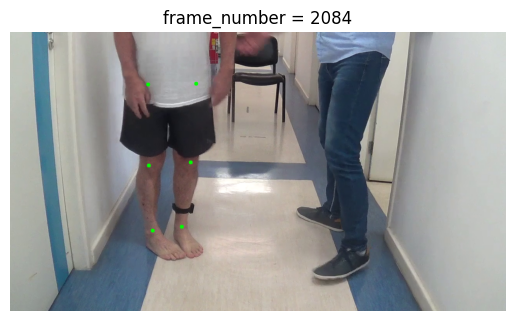

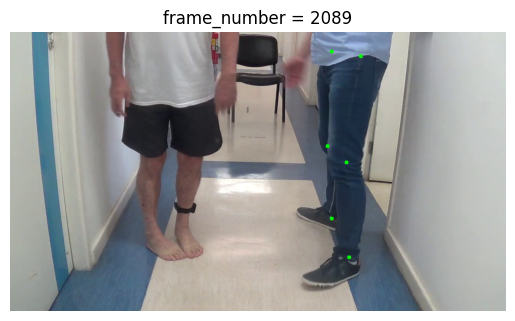

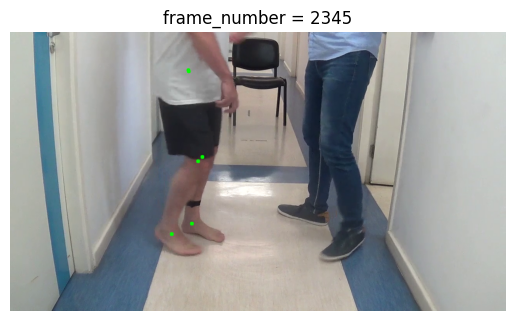

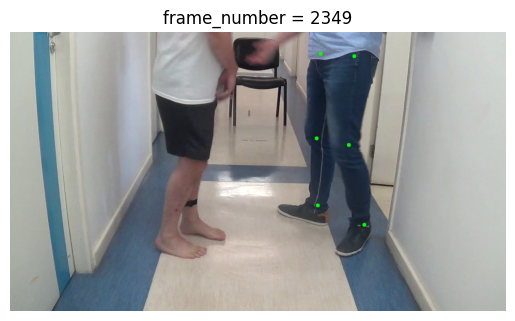

In [ ]:
# Visual check of PDFE05_2 at the jump frames, drawn from the saved file.
video_path='/content/data/Videos/PDFE05_2.mp4'
video=cv2.VideoCapture(video_path)
skeleton = np.load(os.path.join(skeleton_yolo, "PDFE05_2.npy"))
n_frames = len(skeleton)

for n in [2084, 2089, 2345, 2349]:
    video.set(cv2.CAP_PROP_POS_FRAMES, n)   # jump directly to frame n
    ok, frame = video.read()
    if not ok:
        continue
    height, width = frame.shape[:2]

    for j in range (11,17):
          x=skeleton[n,j,0]
          y=skeleton[n,j,1]
          conf = skeleton[n,j,2]
          if np.isnan(x) or np.isnan(y) or conf <0.5:
            continue
          pixel_x = int(x * width)
          pixel_y = int(y * height)
          cv2.circle(frame, (pixel_x, pixel_y), 5, (0, 255, 0), -1)
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title(f"frame_number = {n}")
    plt.axis("off")
    plt.show()
video.release()

**Result:** in PDFE05_2, the patient is selected in frames 2084 and 2345, and the clinician in frames 2089 and 2349. So the frames **between** the jumps are wrong: 2085–2089 and 2346–2349 (9 frames). They are set to missing in section 13.

Now we check the jumps in PDFE24_1:

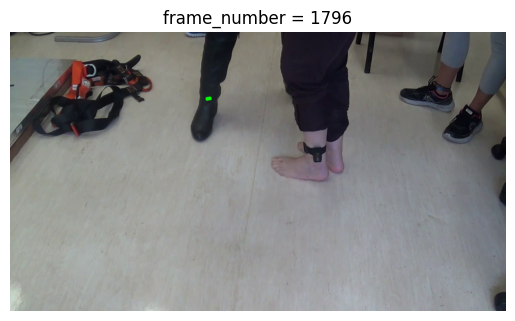

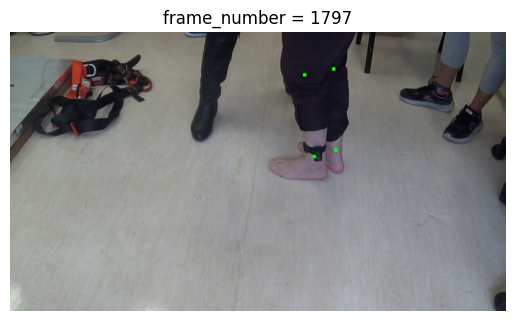

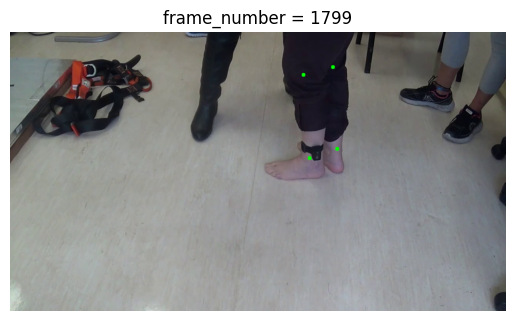

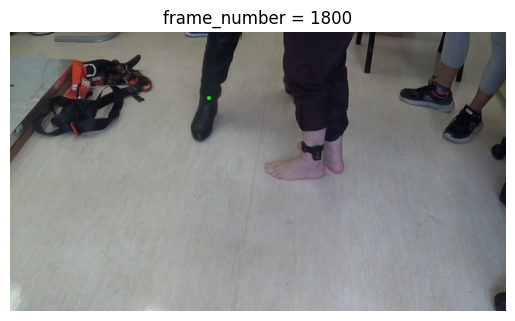

In [ ]:
video_path='/content/data/Videos/PDFE24_1.mp4'
video=cv2.VideoCapture(video_path)
skeleton = np.load(os.path.join(skeleton_yolo, "PDFE24_1.npy"))
n_frames = len(skeleton)

for n in [1796, 1797, 1799, 1800]:
    video.set(cv2.CAP_PROP_POS_FRAMES, n)   # jump directly to frame n
    ok, frame = video.read()
    if not ok:
        continue
    height, width = frame.shape[:2]

    for j in range (11,17):
          x=skeleton[n,j,0]
          y=skeleton[n,j,1]
          conf = skeleton[n,j,2]
          if np.isnan(x) or np.isnan(y) or conf <0.5:
            continue
          pixel_x = int(x * width)
          pixel_y = int(y * height)
          cv2.circle(frame, (pixel_x, pixel_y), 5, (0, 255, 0), -1)
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title(f"frame_number = {n}")
    plt.axis("off")
    plt.show()
video.release()

**Result:** in PDFE24_1, the doctor is selected in frames 1796 and 1800, and the patient in frames 1797–1799. So the doctor is selected **outside** the short segment between the jumps, and the "closest to the image center" rule fails often in this trial: the patient and the doctor are both close to the image center. The patient-selection rule must be changed for this trial.

## 12. Correction of PDFE24_1: person closest to the camera
In PDFE24_1, the patient stands closest to the camera, so her feet appear **lowest** in the image, while the doctor and other people stand further back. For this trial only, the patient is selected as the person whose box reaches lowest in the image (`rule="lowest"`). The other trials keep the default rule: the jump test shows that only PDFE05_2 has a few switches, which are handled in section 13.

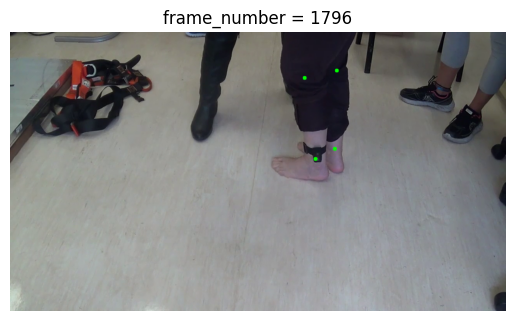

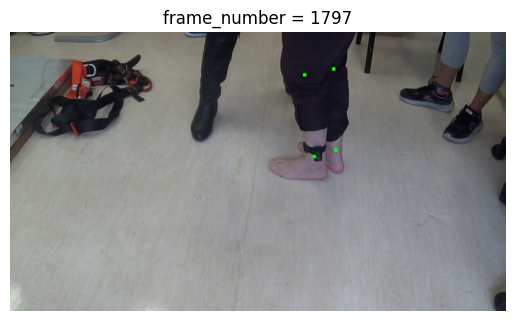

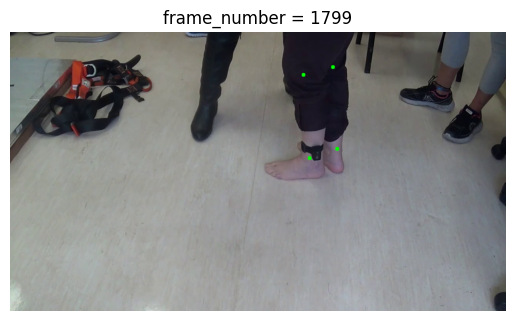

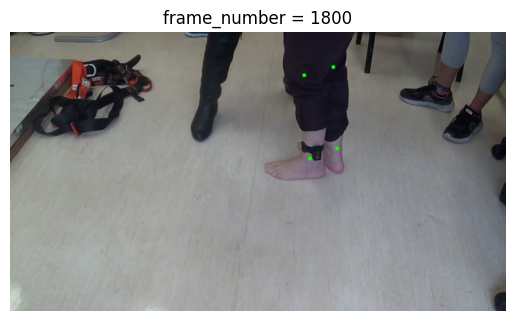

In [ ]:
# Correction of PDFE24_1: extract again with the "lowest" rule (person closest to the camera),
# save it, and draw the joints from the saved file on the same frames as before.
trial = "PDFE24_1"
video_path= f"/content/data/Videos/{trial}.mp4"

# Extract again with the "closest to the camera" rule, and replace the old file
old_file = os.path.join(skeleton_yolo, f"{trial}.npy")
skeleton_new = extract_skeleton(video_path, rule="lowest")
np.save(old_file, skeleton_new)


video=cv2.VideoCapture(video_path)
skeleton_new = np.load(os.path.join(skeleton_yolo, f"{trial}.npy"))
n_frames = len(skeleton_new)

for n in [1796, 1797, 1799, 1800]:
    video.set(cv2.CAP_PROP_POS_FRAMES, n)   # jump directly to frame n
    ok, frame = video.read()
    if not ok:
        continue
    height, width = frame.shape[:2]

    for j in range (11,17):
          x=skeleton_new[n,j,0]
          y=skeleton_new[n,j,1]
          conf = skeleton_new[n,j,2]
          if np.isnan(x) or np.isnan(y) or conf <0.5:
            continue
          pixel_x = int(x * width)
          pixel_y = int(y * height)
          cv2.circle(frame, (pixel_x, pixel_y), 5, (0, 255, 0), -1)
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title(f"frame_number = {n}")
    plt.axis("off")
    plt.show()
video.release()

**Result:** with the "lowest" rule, the **patient** is selected in all four frames (1796, 1797, 1799, 1800).

In [ ]:
# Check the corrected PDFE24_1 file (rule "lowest"): quality, and jumps.
sk = np.load(os.path.join(skeleton_yolo, "PDFE24_1.npy"))

knees_ankles_ok = (sk[:, 13:17, 2] > 0.5).all(axis=1).mean() * 100
ankle_x = sk[:, 15:17, 0].mean(axis=1)
jump_frames = np.where(np.abs(np.diff(ankle_x)) > 0.2)[0]

print(f"Knees and ankles detected: {knees_ankles_ok:.1f}% of frames")
print("Jumps after frames:", jump_frames)

Knees and ankles detected: 93.7% of frames
Jumps after frames: [   1    8   23 2971 3303 3447 3449 3450 3451 3456 3459]


**Result:** knees and ankles are now detected in **93.7%** of frames (68.3% with the "center" rule). The new rule gives 11 jumps, all at the very start (after frames 1, 8, 23) or near the end (after frames 2971, 3303, 3447–3459).

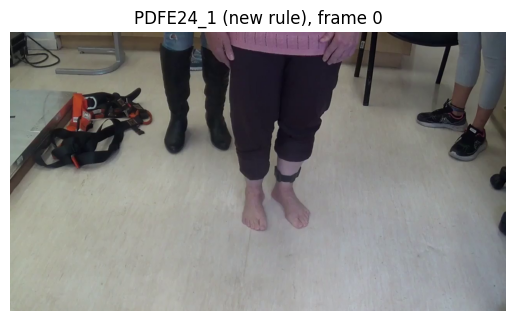

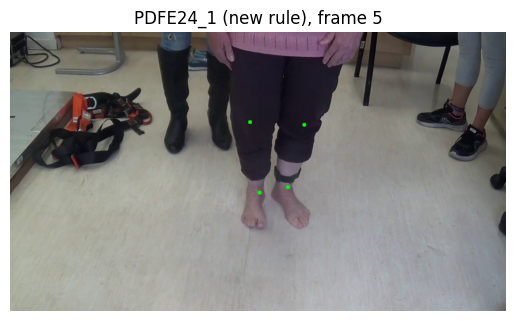

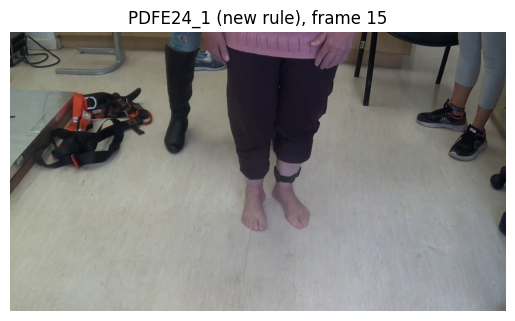

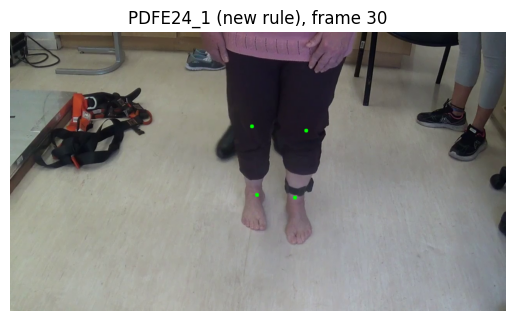

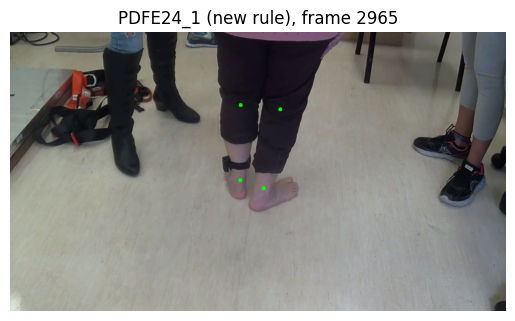

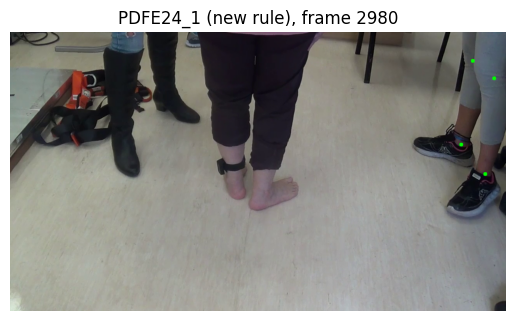

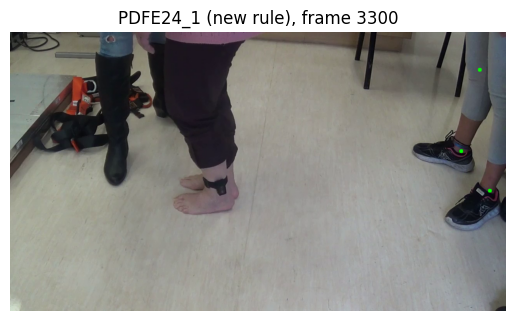

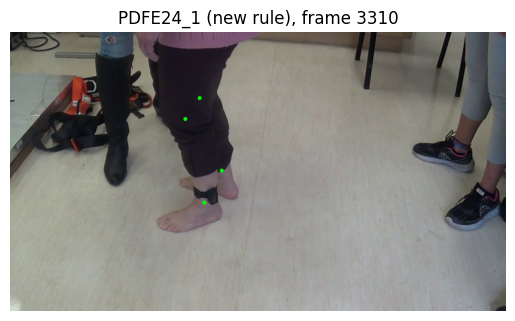

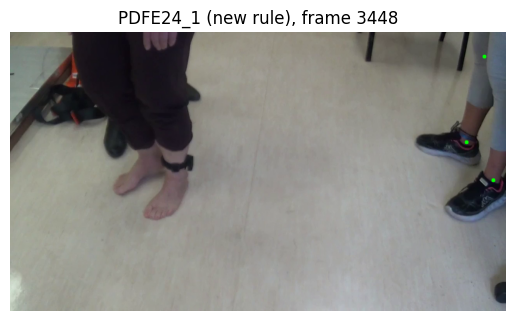

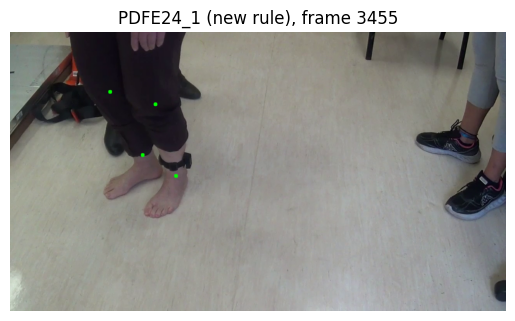

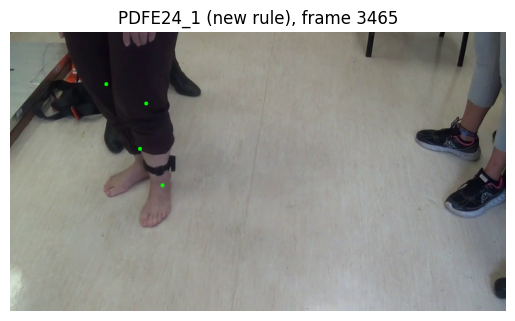

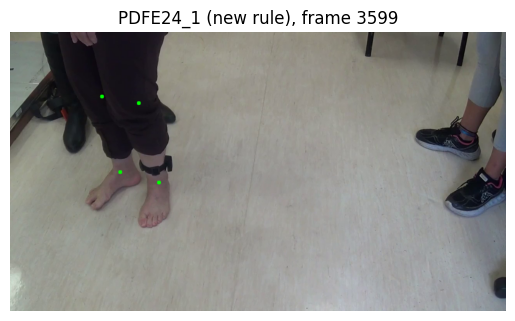

In [ ]:
# Draw knees and ankles (13-16) from the SAVED skeleton file of PDFE24_1 (new rule),
# on frames before and after each new jump.
skeleton_new = np.load(os.path.join(skeleton_yolo, "PDFE24_1.npy"))
video = cv2.VideoCapture('/content/data/Videos/PDFE24_1.mp4')

for n in [0, 5, 15, 30, 2965, 2980, 3300, 3310, 3448, 3455, 3465, 3599]:
    video.set(cv2.CAP_PROP_POS_FRAMES, n)   # jump directly to frame n
    ok, frame = video.read()
    if not ok:
        continue
    height, width = frame.shape[:2]

    for j in range(13, 17):
        x = skeleton_new[n, j, 0]
        y = skeleton_new[n, j, 1]
        conf = skeleton_new[n, j, 2]
        if np.isnan(x) or np.isnan(y) or conf < 0.5:
            continue
        pixel_x = int(x * width)
        pixel_y = int(y * height)
        cv2.circle(frame, (pixel_x, pixel_y), 5, (0, 255, 0), -1)

    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title(f"PDFE24_1 (new rule), frame {n}")
    plt.axis("off")
    plt.show()
video.release()

 A visual check of the frames around these jumps showed:
- frames ≈ 30–2971: the patient is selected, and the frequent switching seen with the "center" rule is gone
- frames 2972–3303 and 3448–3459: a person standing at the **right edge** of the image is selected, because her shoes reach lower in the image than the patient's feet
- frames 0–23: the selection flickers between the patient and that person

These frames are set to missing in section 13.

## 13. Frames set to missing
Two kinds of wrong frames found above are set to NaN in the saved files. The frames are not removed: each file must keep one row per video frame, otherwise all later frames shift in time and no longer match the IMU.

| Trial | Frames | Reason |
|---|---|---|
| PDFE24_1 | 0–23 | flickering at the start |
| PDFE24_1 | 2972–3303 | person at the right edge selected |
| PDFE24_1 | 3448–3459 | same person, a few frames |
| PDFE05_2 | 2085–2089, 2346–2349 | clinician selected |
|7 trials with a metal plate|frames where the knees are below the ankles (found in section 10)|	reflection selected

The wrong-person frames are written by hand (from the visual check), while the reflection frames are found automatically by the rule of section 10.

In [ ]:
# Frames set to NaN (missing):
# 1. wrong person selected (found with the jump test and checked visually, section 11)
# 2. reflection in the metal plate selected (knees below ankles, section 10)
# The frames are not removed, so each file keeps one row per video frame
# and stays aligned in time with the video and the IMU.
bad_frames = {
    "PDFE24_1": [(0, 23), (2972, 3303), (3448, 3459)],
    "PDFE05_2": [(2085, 2089), (2346, 2349)],
}

# All trials with at least one bad frame
trials = set(bad_frames) | {t for t, frames in reflection_frames.items() if len(frames) > 0}

for trial in sorted(trials):
    file = os.path.join(skeleton_yolo, f"{trial}.npy")
    sk = np.load(file)

    missing = np.zeros(len(sk), dtype=bool)              # True = frame becomes missing
    for start, end in bad_frames.get(trial, []):
        missing[start:end + 1] = True                    # end + 1 because Python slices stop before the end
    n_wrong = missing.sum()
    missing[reflection_frames.get(trial, [])] = True
    n_reflection = missing.sum() - n_wrong               # reflection frames not already counted

    sk[missing] = np.nan
    np.save(file, sk)
    print(f"{trial}: {n_wrong} wrong-person + {n_reflection} reflection frames "
          f"= {missing.sum()} set to missing ({missing.mean() * 100:.1f}%)")

PDFE05_2: 9 wrong-person + 0 reflection frames = 9 set to missing (0.2%)
PDFE07_2: 0 wrong-person + 44 reflection frames = 44 set to missing (1.2%)
PDFE19_2: 0 wrong-person + 1 reflection frames = 1 set to missing (0.0%)
PDFE24_1: 368 wrong-person + 0 reflection frames = 368 set to missing (10.2%)
PDFE25_2: 0 wrong-person + 37 reflection frames = 37 set to missing (1.0%)
PDFE26_3: 0 wrong-person + 1 reflection frames = 1 set to missing (0.0%)
PDFE32_1: 0 wrong-person + 1 reflection frames = 1 set to missing (0.0%)
PDFE35_1: 0 wrong-person + 1 reflection frames = 1 set to missing (0.0%)
PDFE35_2: 0 wrong-person + 8 reflection frames = 8 set to missing (0.2%)


**Result**: 470 frames in 9 trials are set to missing:

- wrong person: 368 frames of PDFE24_1 (10.2%) and 9 frames of PDFE05_2 (0.2%)
- reflection: 93 frames in 7 trials: PDFE07_2 (44 frames, 1.2%), PDFE25_2 (37, 1.0%), PDFE35_2 (8, 0.2%), and 1 frame each in PDFE19_2, PDFE26_3, PDFE32_1 and PDFE35_1

PDFE24_1 is the only trial that loses a noticeable part of its video; for these frames, the model will rely on the IMU. All other trials lose at most 1.2% of their frames.

## Summary
- Pose estimation: **YOLO11m-pose**, 17 COCO joints; **4 joints are used: knees and ankles (13–16)**. The hips are outside the image in some trials.
- MediaPipe was rejected: it failed on lower-body-only videos, even with lowered thresholds and cropping (separate notebook).
- Patient selection: the person closest to the image center; for **PDFE24_1 only**, the person closest to the camera (after a visual check).
- One `.npy` file per video on Drive, shape (frames, 17, 3), one row per video frame.
- Quality: a person was detected in all frames. Knees and ankles were detected with confidence > 0.5 in 99.3% of frames on average with the default rule; PDFE24_1 improved from 68.3% to 93.7% with the "lowest" rule.
- Known errors:
set to missing (NaN) in this notebook: wrong person in 368 frames of PDFE24_1 (10.2%) and 9 frames of PDFE05_2; reflection in the metal plate in 93 frames of 7 trials (at most 1.2% of a trial).

**Next step:** align video and IMU per trial, cut the data into windows, create patient-grouped splits.